<a href="https://colab.research.google.com/github/wadeea23/Facial-Emotion-Recognition.lab/blob/main/wadeea_lab_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


**part 1**

In [131]:
zip_path="/content/labNN.zip"
extract_path="/content/labNN"
with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)
print(os.listdir(extract_path))

['train', 'test']


In [132]:
train_path = os.path.join(extract_path, "train")
test_path = os.path.join(extract_path, "test")
print(os.listdir(train_path))
print(os.listdir(test_path))

['neutral', 'surprise', 'angry', 'happy', 'disgust', 'sad', 'fear']
['neutral', 'surprise', 'angry', 'happy', 'disgust', 'sad', 'fear']


In [133]:
emotions = os.listdir(train_path) ## to known every feeling how many pic in thair
for i in emotions:
    print(i, len(os.listdir(os.path.join(train_path, i))))

neutral 4965
surprise 3171
angry 3995
happy 7215
disgust 436
sad 4830
fear 4097


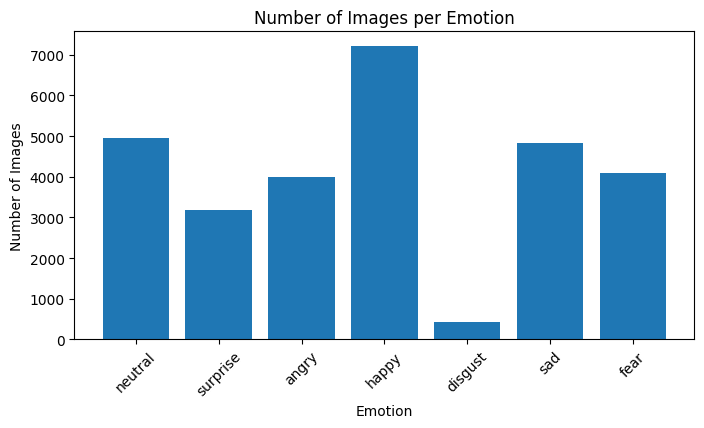

In [134]:
plt.figure(figsize=(8, 4))
plt.bar(emotions, [
    len(os.listdir(os.path.join(train_path, i)))
    for i in emotions])

plt.title("Number of Images per Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [137]:
x_train = [] ## preprocessing & understand data to read the data for step 2
y_train = []

for i in os.listdir(train_path):
    for j in os.listdir(os.path.join(train_path, i)):
        img = Image.open(os.path.join(train_path, i, j)).convert("L")
        x_train.append(np.array(img))
        y_train.append(i)

x_train = np.array(x_train)
y_train = np.array(y_train)

print(x_train.shape)
print(y_train.shape)
print('img_dim',x_train.shape[1:])

(28709, 48, 48)
(28709,)
img_dim (48, 48)


In [138]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_train = to_categorical(y_train)
print(y_train.shape)

(28709, 7)


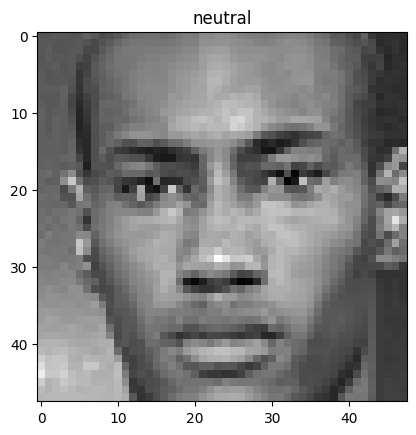

In [139]:
plt.imshow(x_train[0], cmap='gray')
plt.title(le.classes_[np.argmax(y_train[0])])
plt.show()

In [140]:
x_train = x_train / 255

**PART 2**
Neural Network

In [141]:
model = Sequential()
model.add(Input(shape=(48, 48)))
model.add(Flatten())
model.add(Dense(128))
model.add(Activation('relu'))
model.add(Dense(7))
model.add(Activation('softmax'))


In [142]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 7)              │           903 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,943 (1.13 MB)

 Trainable params: 295,943 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

In [143]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [144]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.3506 - loss: 1.5894 - val_accuracy: 0.0000e+00 - val_loss: 9.6436
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4014 - loss: 1.4994 - val_accuracy: 0.0178 - val_loss: 10.5648
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4148 - loss: 1.4702 - val_accuracy: 0.0193 - val_loss: 10.1226
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4248 - loss: 1.4504 - val_accuracy: 0.0099 - val_loss: 14.0900
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.4277 - loss: 1.4363 - val_accuracy: 0.0533 - val_loss: 11.7121
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4334 - loss: 1.4238 - val_accuracy: 0.0174 - val_loss: 16.8333
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4412 - loss: 1.4189 - val_accuracy: 0.0359 - val_loss: 11.7107
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4466 - loss: 1.3966 - val_ac

<Axes: >

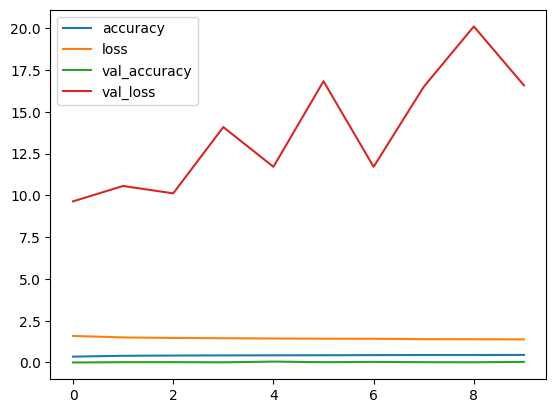

In [146]:
pd.DataFrame(history.history).plot()

In [147]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3682 - loss: 4.4901
Test Accuracy: 0.3682084083557129
Test Loss: 4.490057468414307


In [148]:
y_pred = model.predict(x_test)
y_pred = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [149]:
accuracy_score(y_true, y_pred)

0.3682084146001672

In [150]:
classification_report(y_true, y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


'              precision    recall  f1-score   support\n\n           0       0.24      0.20      0.22       958\n           1       0.00      0.00      0.00       111\n           2       0.00      0.00      0.00      1024\n           3       0.39      0.80      0.53      1774\n           4       0.31      0.40      0.35      1233\n           5       0.38      0.15      0.21      1247\n           6       0.51      0.42      0.46       831\n\n    accuracy                           0.37      7178\n   macro avg       0.26      0.28      0.25      7178\nweighted avg       0.31      0.37      0.31      7178\n'

In [151]:
confusion_matrix(y_true, y_pred)

array([[ 192,    0,    0,  464,  187,   52,   63],
       [  27,    0,    0,   56,   18,    2,    8],
       [ 145,    0,    0,  422,  272,   72,  113],
       [  93,    0,    0, 1418,  152,   70,   41],
       [  97,    0,    0,  522,  497,   70,   47],
       [ 193,    0,    0,  498,  309,  183,   64],
       [  60,    0,    0,  245,  144,   29,  353]])

**part 3 **

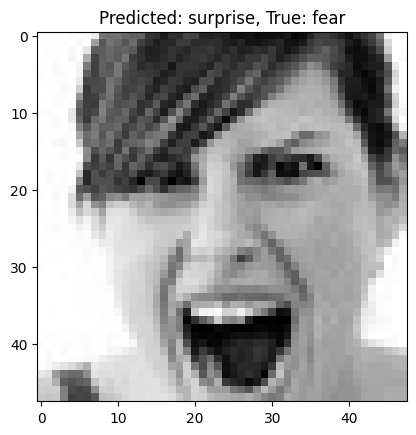

In [152]:
errors = np.where(y_pred != y_true)
for i in errors[0]:
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Predicted: {le.classes_[y_pred[i]]}, True: {le.classes_[y_true[i]]}")

The model made mistakes because some emotions look similar. Some images may also be unclear or have different lighting.

In [153]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [154]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4557 - loss: 1.3789 - val_accuracy: 0.0326 - val_loss: 17.5478
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4599 - loss: 1.3598 - val_accuracy: 0.0275 - val_loss: 22.5994
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4658 - loss: 1.3568 - val_accuracy: 0.0167 - val_loss: 24.6391
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4699 - loss: 1.3436 - val_accuracy: 0.0242 - val_loss: 20.6970
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4717 - loss: 1.3381 - val_accuracy: 0.0284 - val_loss: 27.5680
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.4783 - loss: 1.3310 - val_accuracy: 0.0463 - val_loss: 31.7928


In [155]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3675 - loss: 4.7081
Test Accuracy: 0.3675118386745453
Test Loss: 4.7080535888671875


**part 4**

In [8]:
%%writefile /content/app.py
import streamlit as st
import numpy as np
import pickle
from PIL import Image
from tensorflow.keras.models import load_model

model.save("emotion_model.keras")

with open("emotion_classes.json", "w") as f:
    json.dump(le.classes_.tolist(), f)

files.download("emotion_model.keras")
files.download("emotion_classes.json")


Writing /content/app.py


In [9]:
!pip install streamlit pyngrok

In [15]:

%%writefile /content/app.py
import streamlit as st
import numpy as np
import pickle
from PIL import Image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model("/content/emotion_model.keras")

# Load emotion names
with open("/content/emotion_classes.pkl", "rb") as f:
    classes = pickle.load(f)

# App title
st.title("Facial Emotion Detector")
st.write("Upload an image or take a photo to predict the emotion.")

# Select image
uploaded_image = st.file_uploader(
    "Upload an Image",
    type=["jpg", "jpeg", "png"]
)

camera_image = st.camera_input("Or Take a Photo")

if uploaded_image is not None:
    image_file = uploaded_image
else:
    image_file = camera_image

# Display and predict
if image_file is not None:

    image = Image.open(image_file)
    st.image(image, caption="Your Image", width=300)

    if st.button("Predict Emotion"):

        # Prepare image
        image = image.convert("L")
        image = image.resize((48, 48))

        image = np.array(image) / 255.0
        image = np.expand_dims(image, axis=0)

        # Predict
        prediction = model.predict(image, verbose=0)[0]
        best_index = np.argmax(prediction)

        # Show result
        st.subheader("Predicted Emotion")
        st.success(classes[best_index].capitalize())

        # Show probabilities
        st.subheader("Emotion Probabilities")

        for i in range(len(classes)):
            st.write(classes[i].capitalize())
            st.progress(float(prediction[i]))
            st.write(f"{prediction[i] * 100:.2f}%")

st.divider()
st.caption("Neural Network Project")


Overwriting /content/app.py


In [11]:
!streamlit run /content/app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/log.txt 2>&1 &

In [16]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>